<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 20: Probabilistic PCA and Reconstruction Analysis

### Problem Statement:
In a smart factory, a sensor network produces readings with random noise and occasional missing values. Engineers need a model that accounts for noise explicitly. We will apply Probabilistic PCA (PPCA) to multivariate sensor readings (temperature, vibration, pressure, current, etc.) with added Gaussian noise, compare its reconstruction with standard PCA, and generate synthetic sensor samples.

## Task 1: Explaining the PPCA Generative Model

Probabilistic PCA formulation extends classical PCA into a probabilistic latent variable framework.
The generative model is defined as:

$$x = Wz + \mu + \epsilon$$

where:
*   $x \in \mathbb{R}^d$ is the observed multivariate sensor reading vector (dimension $d$).
*   $z \in \mathbb{R}^q$ is the latent variable vector (dimension $q < d$), representing the underlying true state of the system. We assume $z \sim \mathcal{N}(0, I)$.
*   $W \in \mathbb{R}^{d \times q}$ is the factor loading matrix that maps the latent space to the data space.
*   $\mu \in \mathbb{R}^d$ is the mean parameter vector of the data.
*   $\epsilon \in \mathbb{R}^d$ represents the sensor observation noise, modeled as an isotropic Gaussian process: $\epsilon \sim \mathcal{N}(0, \sigma^2 I)$, where $\sigma^2$ is the noise variance.

Under this formulation, the observed variables are also Gaussian distributed:
$$x|z \sim \mathcal{N}(Wz + \mu, \sigma^2 I)$$
$$x \sim \mathcal{N}(\mu, C)$$
where $C = WW^T + \sigma^2 I$ is the model covariance matrix.

## Setup: Generate Synthetic Sensor Data with Noise

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate clean sensor readings (5 dimensions: temp, vibration, pressure, current, humidity)
n_samples = 500
d_features = 5

# Latent true state (e.g., 2 hidden processes driving 5 sensors)
true_latent = np.random.randn(n_samples, 2)

# Mapping from 2D latent space to 5D observation space
true_W = np.array([
    [0.8,  0.1],
    [-0.5, 0.9],
    [0.9,  0.4],
    [0.2, -0.7],
    [0.6,  0.6]
])
true_mu = np.array([25.0, 1.2, 101.3, 5.0, 45.0]) # baseline means

clean_data = np.dot(true_latent, true_W.T) + true_mu

# Add known Gaussian noise
true_noise_std = 0.4
noise = np.random.normal(loc=0.0, scale=true_noise_std, size=clean_data.shape)
noisy_data = clean_data + noise

print("Noisy Data Shape:", noisy_data.shape)
print("True noise variance (sigma^2):", true_noise_std**2)

Noisy Data Shape: (500, 5)
True noise variance (sigma^2): 0.16000000000000003


## Task 2 & 3: Fit PPCA and Estimate Noise Variance $\sigma^2$

Scikit-learn's `PCA` class implements Probabilistic PCA via Maximum Likelihood estimation when we fit the model. It automatically estimates the noise variance $\sigma^2$ (accessible via `noise_variance_` attribute).

In [2]:
# Fit PPCA (using Scikit-learn's PCA which estimates noise variance under the PPCA framework)
q_components = 2
ppca = PCA(n_components=q_components)
ppca.fit(noisy_data)

estimated_noise_variance = ppca.noise_variance_
print(f"Estimated Noise Variance (sigma^2) with {q_components} components: {estimated_noise_variance:.4f}")
print(f"True Noise Variance (sigma^2): {true_noise_std**2:.4f}")

Estimated Noise Variance (sigma^2) with 2 components: 0.1537
True Noise Variance (sigma^2): 0.1600


## Task 4: Reconstruction Error Analysis against Component Count

We will reconstruct the clean sensor readings from noisy representations using different numbers of components ($1$ to $5$) and evaluate the reconstruction performance compared to standard Reconstruction techniques.

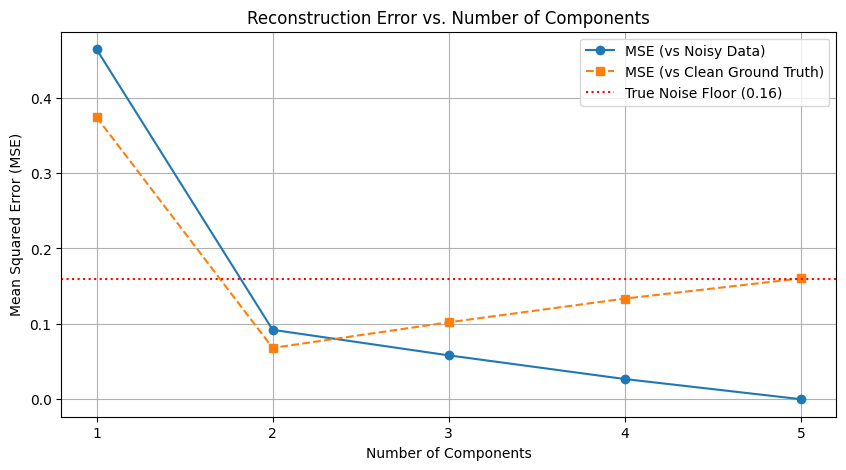

In [3]:
components_range = range(1, d_features + 1)
reconstruction_errors_noisy = []
reconstruction_errors_clean = []

for q in components_range:
    pca_model = PCA(n_components=q)
    # Fit on noisy data
    pca_model.fit(noisy_data)

    # Reconstruct data: Project and map back to data space
    latent_representation = pca_model.transform(noisy_data)
    reconstructed_data = pca_model.inverse_transform(latent_representation)

    # MSE against original noisy inputs
    mse_noisy = np.mean((noisy_data - reconstructed_data) ** 2)
    reconstruction_errors_noisy.append(mse_noisy)

    # MSE against ground truth clean data (denoising capability evaluation)
    mse_clean = np.mean((clean_data - reconstructed_data) ** 2)
    reconstruction_errors_clean.append(mse_clean)

# Visualization
plt.figure(figsize=(10, 5))
plt.plot(components_range, reconstruction_errors_noisy, 'o-', label='MSE (vs Noisy Data)')
plt.plot(components_range, reconstruction_errors_clean, 's--', label='MSE (vs Clean Ground Truth)')
plt.axhline(y=true_noise_std**2, color='r', linestyle=':', label='True Noise Floor (0.16)')
plt.title('Reconstruction Error vs. Number of Components')
plt.xlabel('Number of Components')
plt.ylabel('Mean Squared Error (MSE)')
plt.xticks(components_range)
plt.legend()
plt.grid(True)
plt.show()

## Task 5: Generate New Synthetic Sensor Samples

Using the generative model parameters $W$, $\mu$, and estimated $\sigma^2$, we can simulate new synthetic sensor data samples.

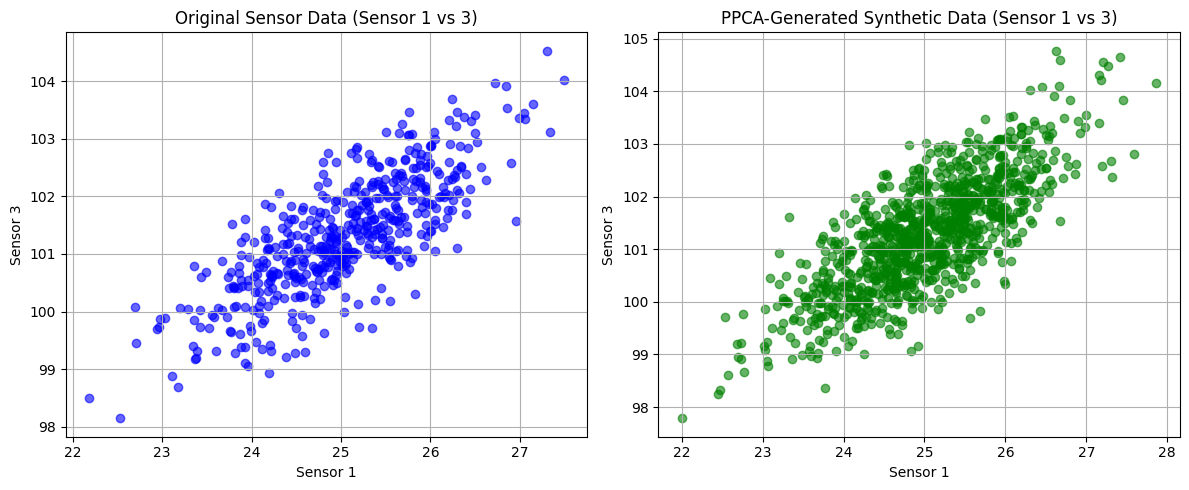

In [4]:
# Retrieve fitted parameters
# W (components_ x n_features) needs to be transposed to represent (d x q)
W_estimated = ppca.components_.T * np.sqrt(ppca.explained_variance_)[:q_components]
mu_estimated = ppca.mean_
sigma2_estimated = ppca.noise_variance_

# Generate new synthetic latent states z ~ N(0, I)
n_synthetic_samples = 1000
synthetic_z = np.random.randn(n_synthetic_samples, q_components)

# Map back to sensor space and add reconstructed isotropic Gaussian noise
synthetic_clean = np.dot(synthetic_z, W_estimated.T) + mu_estimated
synthetic_noise = np.random.normal(loc=0.0, scale=np.sqrt(sigma2_estimated), size=synthetic_clean.shape)
synthetic_sensors = synthetic_clean + synthetic_noise

# Let's visualize and compare original noisy data vs generated synthetic data distributions
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(noisy_data[:, 0], noisy_data[:, 2], alpha=0.6, color='blue', label='Original Noisy')
plt.title('Original Sensor Data (Sensor 1 vs 3)')
plt.xlabel('Sensor 1')
plt.ylabel('Sensor 3')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(synthetic_sensors[:, 0], synthetic_sensors[:, 2], alpha=0.6, color='green', label='Synthetic')
plt.title('PPCA-Generated Synthetic Data (Sensor 1 vs 3)')
plt.xlabel('Sensor 1')
plt.ylabel('Sensor 3')
plt.grid(True)

plt.tight_layout()
plt.show()